Using backend: tensorflow

2022-11-01 22:47:47.103549: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0


no uniform points
Compiling model...
'compile' took 0.000379 s



2022-11-01 22:47:49.281729: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcuda.so.1
2022-11-01 22:47:49.354715: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:81:00.0 name: Quadro RTX 8000 computeCapability: 7.5
coreClock: 1.77GHz coreCount: 72 deviceMemorySize: 47.46GiB deviceMemoryBandwidth: 625.94GiB/s
2022-11-01 22:47:49.354734: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-01 22:47:49.357370: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-01 22:47:49.357400: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublasLt.so.11
2022-11-01 22:47:49.358228: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcufft.so.10

Training model...



2022-11-01 22:47:51.681405: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:176] None of the MLIR Optimization Passes are enabled (registered 2)
2022-11-01 22:47:51.706274: I tensorflow/core/platform/profile_utils/cpu_utils.cc:114] CPU Frequency: 3000030000 Hz
2022-11-01 22:47:51.808086: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-01 22:47:52.177484: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublasLt.so.11


Step      Train loss              Test loss               Test metric   
0         [1.45e+00, 1.21e-01]    [1.43e+00, 1.19e-01]    [9.63e-01]    
1000      [2.41e-02, 9.05e-04]    [2.53e-02, 9.29e-04]    [3.86e-01]    
2000      [1.29e-03, 1.61e-04]    [1.27e-03, 1.61e-04]    [4.26e-01]    
3000      [6.17e-04, 1.22e-04]    [6.20e-04, 1.28e-04]    [4.20e-01]    
4000      [3.12e-04, 8.25e-05]    [3.10e-04, 8.80e-05]    [4.26e-01]    
5000      [1.73e-04, 4.17e-05]    [1.70e-04, 4.56e-05]    [4.38e-01]    
6000      [1.20e-04, 5.45e-05]    [1.21e-04, 5.82e-05]    [4.47e-01]    
7000      [7.42e-05, 7.53e-06]    [7.55e-05, 7.97e-06]    [4.57e-01]    
8000      [3.55e-05, 4.20e-06]    [3.68e-05, 4.12e-06]    [4.60e-01]    
9000      [1.79e-05, 2.97e-06]    [1.81e-05, 2.87e-06]    [4.60e-01]    
10000     [1.15e-05, 2.60e-06]    [1.15e-05, 2.49e-06]    [4.59e-01]    

Best model at step 10000:
  train loss: 1.41e-05
  test loss: 1.40e-05
  test metric: [4.59e-01]

'train' took 61.080087 s


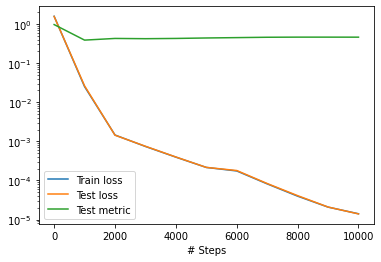

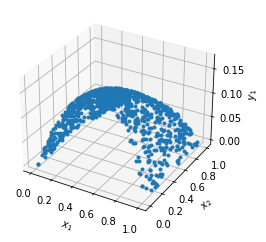

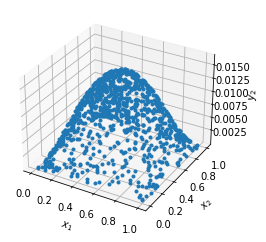

Theta:=  7902


In [1]:
import os
os.environ['DDEBACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '4'

import deepxde as dde 
from deepxde.backend import tf
from functools import reduce
import argparse

parser = argparse.ArgumentParser(description='Set parameters')

k=2
epochs = 10000
seed = 1234

dde.config.set_random_seed(seed)

#class TensorGeometryXTime:
import numpy as np

class GeometryXGeometry:
    def __init__(self, geometry, k):
        self.geometry = geometry
        self.dim = geometry.dim ** k
        self.k = k
    
    def random_points(self, n, random="pseudo"):
        xx = []
        for i in range(self.k):
            xx.append(self.geometry.random_points(n, random=random))
        return np.hstack(xx)
    
    def uniform_points(self, n, boundary=False):
        print('no uniform points')
        return self.random_points(n)
    
"""Backend supported: tensorflow.compat.v1, tensorflow, pytorch"""
import deepxde as dde
import numpy as np

sigma = 1
N = 4000
N_test = 1000
lambd = 1
kappa = 0

#geom = dde.geometry.Interval(0, np.pi)
geom = dde.geometry.Interval(0, 1)
Geom = GeometryXGeometry(geom, k)

def func(x):
    u_list = [-1/6 * x[:, i:i+1] * (x[:, i:i+1] ** 2 - 1) for i in range(k)]
    u = reduce(lambda x1, x2: x1 * x2, u_list)
    c = np.exp(1/2 * k ** 2 * sigma ** 2)
    
    res_list = k * [None]
    for i in range(k-1):
        res_list[i] = 0 * u
    res_list[-1] = c * u
    return np.hstack(res_list)

def hatu(x):
    return -1/6 * x * (x ** 2 - 1)

def pde(x, y):
    V0, V1 = y[:, 0:1], y[:, 1:2]
    dV0_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    dV1_yy = dde.grad.hessian(y, x, component=1, i=1, j=1)
    
    C = tf.exp(x[:, 0:1] ** 2 - x[:, 1:2] ** 2)
    
    L0 =  -dV0_xx - lambd * V0 ** 3 - C
    L1 = -dV1_yy - lambd * V1 ** 3 - V0
    return [L0, L1]

data = dde.data.PDE(Geom, pde, [], train_distribution="pseudo", num_domain=N, solution=func, num_test=N_test)


layer_size = [k] + [50] * 4 + [k]
activation = 'tanh'
initializer = 'Glorot uniform'
net = dde.nn.FNN(layer_size, activation, initializer)

def output_transform(x, y):
    transf_list = [x[:, i:i+1] * (x[:, i:i+1] - 1) for i in range(k)]
    transf = reduce(lambda x1, x2: x1 * x2, transf_list)
    y_list = [y[:, i:i+1] for i in range(k)]
    ys_list = k * [None]
    for i in range(k-1):
        ys_list[i] = y_list[i]
    ys_list[-1] = transf * y_list[-1]
    ys = tf.concat(ys_list, axis=1)
    return ys

net.apply_output_transform(output_transform)

def l2_error(y_true, y_pred):
    pred = y_true - y_pred
    return np.linalg.norm(pred[:, k-1:k])/np.linalg.norm(y_true[:, k-1:k]) 


model = dde.Model(data, net)
model.compile("adam", lr=1e-4, metrics=[l2_error])
#model.compile("adam", lr=1e-4, decay = ("inverse time", 5000, 0.5), metrics=["l2 relative error"])

losshistory, train_state = model.train(epochs=epochs)

dde.saveplot(losshistory, train_state, issave=True, isplot=True)
 
result = np.sum(
            [np.prod(v.get_shape().as_list()) for v in model.net.trainable_variables]
        )
print('Theta:= ', result)

x = np.array([np.arange(101)/100]).T
x_list = [x.T for i in range(k)]
xx = np.concatenate(x_list).T
sol = func(xx)[:, k-1:k]
pred = model.predict(xx)[:, k-1:k]

name = 'results/mo_diag_pred' + str(k) 
test = np.save(name,pred)

name = 'results/mo_diag_exact' + str(k) 
test = np.save(name,sol)

name = 'results/mo_diag_x' + str(k) 
test = np.save(name,xx[:, 0:1])


#print("# Parameters:", np.sum([np.prod(v.get_shape().as_list()) for v in tf.trainable_variables()]))


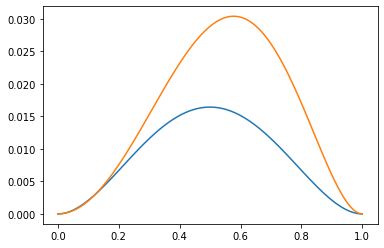

In [2]:
from matplotlib import pyplot as plt

plt.plot(x.ravel(),pred.ravel(), label='pred')
plt.plot(x.ravel(),sol.ravel(), label='exact')

Relative error =  0.4606016843989975


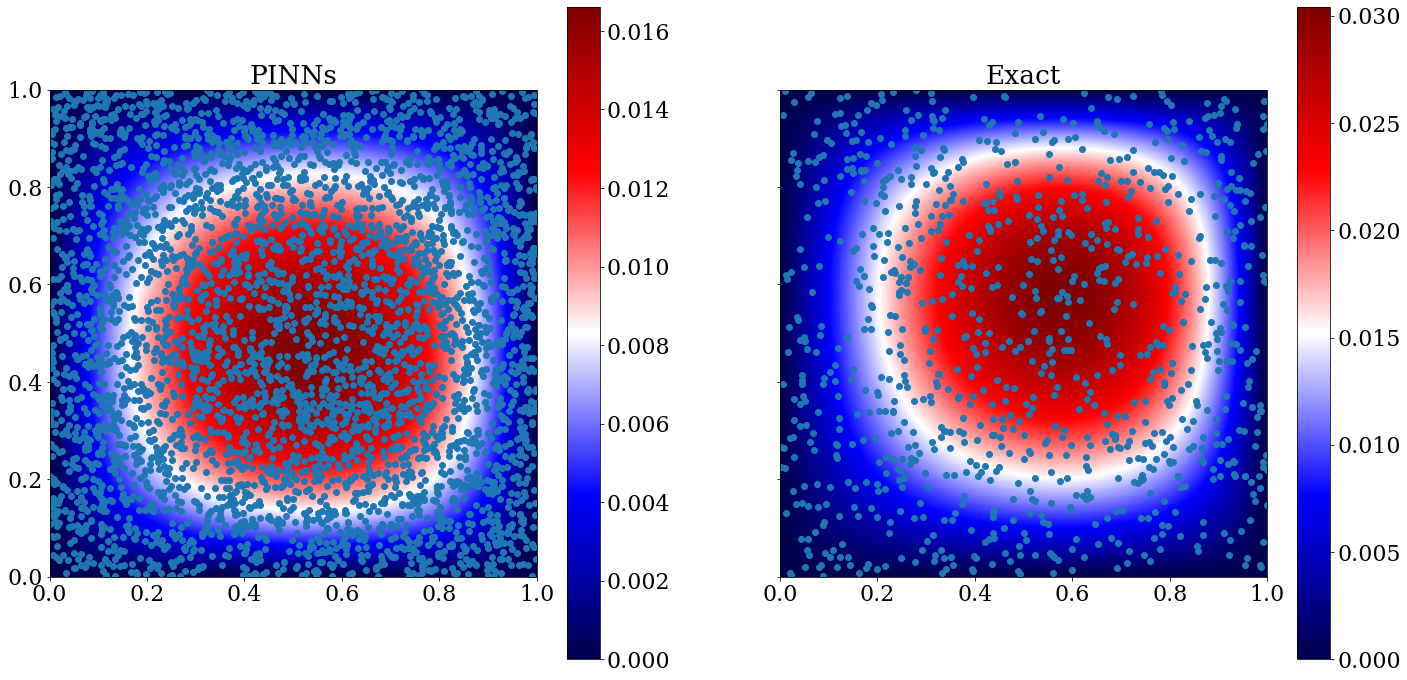

In [3]:
from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

points_2d = points[:2, :]

#sol = func(xx)[:, k-1:k]
#pred = model.predict(xx)[:, k-1:k]

u_exact = func(points_2d.T)[:, k-1:k]
u_sca = model.predict(points_2d.T)[:, k-1:k]
#u_exact = func(points_2d.T)
#u_sca = model.predict(points_2d.T)
u_exact = u_exact.reshape((Nx, Ny))
u_sca = u_sca.reshape((Nx, Ny))

'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run




diff = u_exact-u_sca
error = np.linalg.norm(diff)/np.linalg.norm(u_exact)
print('Relative error = ', error)

'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)



fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize = (24,12))

pcm = ax1.imshow(np.fliplr(u_sca).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='PINN')

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)

pcm = ax2.imshow(np.fliplr(u_exact).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label = 'Exact')


ax2.scatter(data.test_x[:, 0:1], data.test_x[:, 1:2])
ax1.scatter(data.train_x[:, 0:1], data.train_x[:, 1:2])
#ax1.axis('off')
ax1.set_title('PINNs')
ax2.set_title('Exact')
fig.colorbar(pcm, ax = ax2)

plt.savefig('img.png')